In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from jax.scipy.stats import multivariate_normal, norm
from jax.scipy.special import logsumexp

In [ ]:
b = -1.05
sigma_y = 0.7
y = 0.0

In [11]:
def log_prior(theta):
    return multivariate_normal.logpdf(theta, mean=jnp.array([0,0]), cov=jnp.identity(2))

def log_likelihood(y, theta, b=b, sigma_y=sigma_y):
    return norm.logpdf(y, loc=theta[1] - b * theta[0]**2, scale=sigma_y)

def log_target(theta, y):
    return log_likelihood(y, theta) + log_prior(theta)

In [12]:
K = 7
key = jax.random.PRNGKey(0)
key, subkey = jax.random.split(key)

params = {
    "mu": 0.85 * jax.random.normal(subkey, shape=(K, 2)),
    "log_sigma": jnp.full((K, 2), -0.7),
    "logits": jnp.zeros(K)
}

def log_gaussian_mixture(theta, params):
    mu = params["mu"]
    sigma = jnp.exp(params["log_sigma"])

    log_pi = jax.nn.log_softmax(params["logits"])
    
    log_normal_components = jax.vmap(
        lambda m, s: multivariate_normal.logpdf(
            x=theta, mean=m, cov=jnp.diag(s**2)
        )
    )(mu, sigma)

    
    return logsumexp(log_pi + log_normal_components)

print("Mixture weights:", jax.nn.softmax(params["logits"]))
print("Log mixture density at (0, 0):", log_gaussian_mixture(jnp.array([0., 0.]), params))

Mixture weights: [0.14285715 0.14285715 0.14285715 0.14285715 0.14285715 0.14285715
 0.14285715]
Log mixture density at (0, 0): -2.1638494


In [13]:
def sample_theta_from_q(key, params, num_samples=1):
    
    key1, key2 = jax.random.split(key)

    k = jax.random.categorical(key1, params['logits'], shape=(num_samples,))

    mu_k = params['mu'][k]
    sigma_k = jnp.exp(params['log_sigma'][k])
    cov_k = jax.vmap(lambda s: jnp.diag(s**2))(sigma_k)

    keys = jax.random.split(key2, num_samples)


    return jax.vmap(lambda key_i, mu, cov: jax.random.multivariate_normal(key_i, mean=mu, cov=cov))(keys, mu_k, cov_k)
    

In [14]:
# sample_theta_from_q(key, params, num_samples=100)
# params['mu']

In [15]:
def gradient_elbo(key, params, y, num_samples=10):
    
    samples = sample_theta_from_q(key, params, num_samples=num_samples)
    
    log_q = jax.vmap(lambda theta: log_gaussian_mixture(theta, params))(samples)
    log_p = jax.vmap(lambda theta: log_target(theta, y))(samples)

    grad_log_q = jax.vmap(
        jax.grad(
            lambda theta, phi: log_gaussian_mixture(theta, phi),
            argnums=1
        ),
        in_axes=(0, None)
    )(samples, params)

    grad_elbo = jax.tree.map(
        lambda g: jnp.mean(
            (log_p - log_q).reshape(
                (num_samples,) + (1,) * (g.ndim - 1)
            ) * g,
            axis=0
        ),
        grad_log_q
    )

    return grad_elbo

In [16]:
key = jax.random.PRNGKey(123)
learning_rate = 0.01
num_steps = 2000

@jax.jit
def train_step(params, key):

    gradients = gradient_elbo(
        key, params, y, num_samples=200
    )

    params = jax.tree.map(
        lambda p, g: p + learning_rate * g,
        params, gradients
    )

    return params


for step in range(num_steps):
    key, subkey = jax.random.split(key)
    params = train_step(params, subkey)

print(
    "Final mixture weights:",
    np.asarray(jax.nn.softmax(params["logits"]))
)

# plt.figure(figsize=(8, 3))
# plt.plot(elbo_history)
# plt.xlabel("Iteration")
# plt.ylabel("Estimated ELBO")
# plt.title("Gaussian mixture VI")
# plt.show()

# print("Final mixture weights:", np.asarray(jax.nn.softmax(params["logits"])))

Final mixture weights: [0.06214252 0.24636601 0.13696207 0.15824057 0.07041547 0.18945782
 0.13641557]


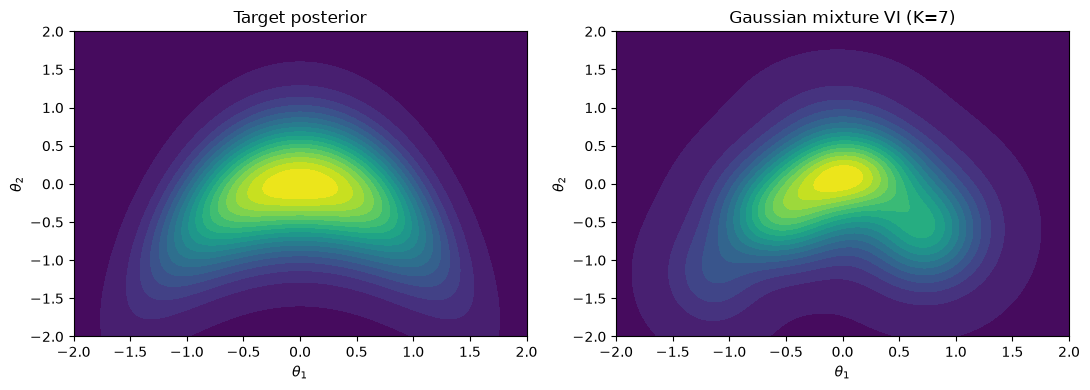

In [17]:
x1 = np.linspace(-2.0, 2.0, 200)
x2 = np.linspace(-2.0, 2.0, 200)
X1, X2 = np.meshgrid(x1, x2)
points = jnp.asarray(np.column_stack([X1.ravel(), X2.ravel()]))

log_p = jax.vmap(lambda theta:  jnp.exp(log_target(theta, y)))(points)
log_q = jax.vmap(lambda theta:  jnp.exp(log_gaussian_mixture(theta, params)))(points)

P = np.exp(np.asarray(log_p).reshape(X1.shape) - float(jnp.max(log_p)))
Q = np.exp(np.asarray(log_q).reshape(X1.shape) - float(jnp.max(log_q)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].contourf(X1, X2, P, levels=20)
axes[0].set_title("Target posterior")
axes[1].contourf(X1, X2, Q, levels=20)
axes[1].set_title(f"Gaussian mixture VI (K={K})")

for ax in axes:
    ax.set_xlabel(r"$\theta_1$")
    ax.set_ylabel(r"$\theta_2$")

plt.tight_layout()
plt.show()

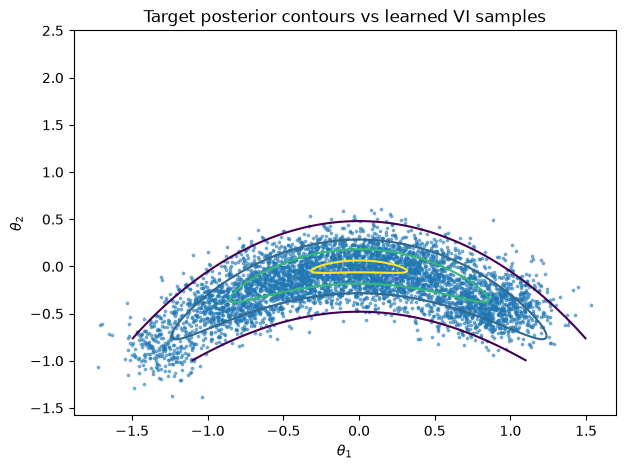

In [10]:
key, subkey = jax.random.split(key)
samples = sample_theta_from_q(subkey, params, num_samples=5000)

# Grid
x = jnp.linspace(-1.5, 1.5, 300)
z = jnp.linspace(-1., 2.5, 300)

X, Z = jnp.meshgrid(x, z)
grid = jnp.stack([X.ravel(), Z.ravel()], axis=1)

# Target density
P = jax.vmap(
    lambda theta:  jnp.exp(log_target(theta, y))
)(grid).reshape(X.shape)

# Exclude very low density contours
levels = np.linspace(
    0.05 * float(P.max()),
    0.95 * float(P.max()),
    4
)

plt.figure(figsize=(7, 5))

# Colored banana contours
contours = plt.contour(
    X, Z, P,
    levels=levels,
    cmap="viridis",
    linewidths=1.5
)

# Learned mixture samples
plt.scatter(
    samples[:, 0],
    samples[:, 1],
    s=3,
    alpha=0.5,
    color="tab:blue"
)

plt.xlabel(r"$\theta_1$")
plt.ylabel(r"$\theta_2$")
plt.title("Target posterior contours vs learned VI samples")

# plt.xlim(-1.3, 1.3)
# plt.ylim(-2, 0.8)
plt.show()